In [7]:
# import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
# upload Cleaned dataset
df=pd.read_csv("Cleaned_dataset.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,movie,dick johnson is dead,kirsten johnson,united states,2021-09-25,2020,pg-13,90 min,documentaries
1,s3,tv show,ganglands,julien leclercq,france,2021-09-24,2021,tv-ma,1 season,"crime tv shows, international tv shows, tv act..."
2,s6,tv show,midnight mass,mike flanagan,united states,2021-09-24,2021,tv-ma,1 season,"tv dramas, tv horror, tv mysteries"
3,s14,movie,confessions of an invisible girl,bruno garotti,brazil,2021-09-22,2021,tv-pg,91 min,"children & family movies, comedies"
4,s8,movie,sankofa,haile gerima,united states,2021-09-24,1993,tv-ma,125 min,"dramas, independent movies, international movies"


In [9]:
# check dataset shape 
print(df.shape)

(8790, 10)


In [10]:
# Step 1: Prepare release-year data.
if "release_year" not in df.columns:
    raise ValueError("release_year column not found in dataset")

# Convert release_year into numeric format
df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

# Remove missing release years
df = df.dropna(subset=["release_year"]).copy()

# Convert year into integer
df["release_year"] = df["release_year"].astype(int)

# Count content released in each year
yearly_content = (
    df.groupby("release_year")
      .size()
      .reset_index(name="content_count")
      .sort_values("release_year")
)

print("Cleaned Data:")
print(yearly_content.head(10))

print("\nTotal yearly records:", len(yearly_content))

Cleaned Data:
   release_year  content_count
0          1925              1
1          1942              2
2          1943              3
3          1944              3
4          1945              4
5          1946              2
6          1947              1
7          1954              2
8          1955              3
9          1956              2

Total yearly records: 74


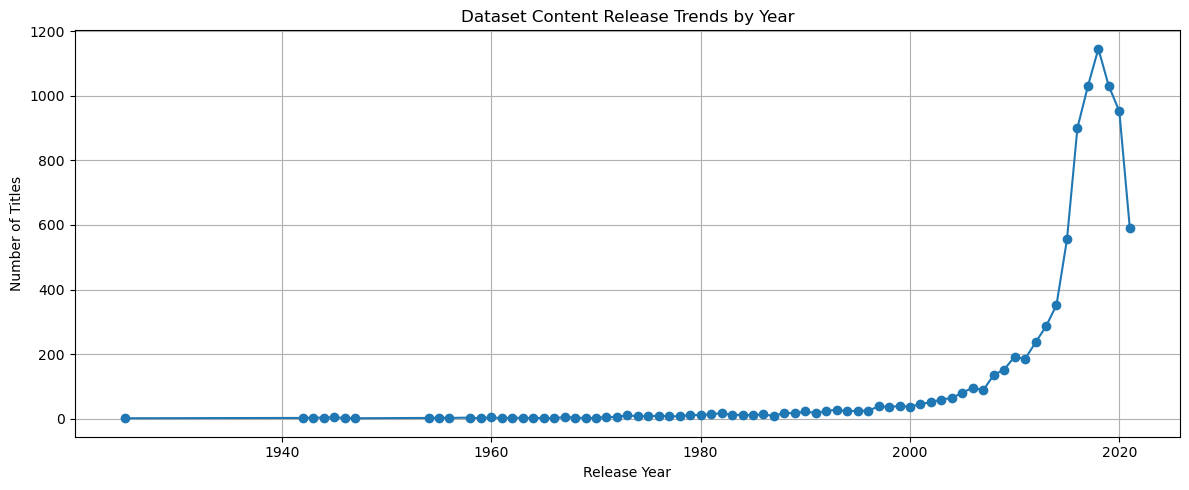

In [19]:
# Step 2: Analyze yearly content trends
plt.figure(figsize=(12, 5))
plt.plot(yearly_content["release_year"],yearly_content["content_count"],marker="o")
plt.title("Dataset Content Release Trends by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
# Step 3: Build forecasting models.
forecast_data = yearly_content[
    yearly_content["release_year"] >= 2000
].copy()

forecast_data = forecast_data.sort_values("release_year")

if len(forecast_data) < 10:
    raise ValueError(
        "Not enough yearly records. Check the dataset and year range."
    )

# Features (X) and target (y)
X = forecast_data[["release_year"]]
y = forecast_data["content_count"]

# Keep the latest 20% of years for testing
split_index = int(len(forecast_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training years:", X_train["release_year"].min(),
      "to", X_train["release_year"].max())
print("Testing years:", X_test["release_year"].min(),
      "to", X_test["release_year"].max())

Training records: 17
Testing records: 5
Training years: 2000 to 2016
Testing years: 2017 to 2021


In [13]:
# train the model 
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predict content count for test years
test_predictions = model.predict(X_test)

# Negative counts are not meaningful
test_predictions = np.maximum(test_predictions, 0)

print("Model training completed!")
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Model training completed!
Slope: 35.985294117647065
Intercept: -72051.76470588236


In [14]:
# Evalute performance 
mae = mean_absolute_error(y_test, test_predictions)
mse=mean_squared_error(y_test,test_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, test_predictions)

print("MAE:", round(mae, 2))
print("MSE:",round(mse,2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

MAE: 380.66
MSE: 174719.57
RMSE: 417.99
R2 Score: -3.87


In [15]:
# Find the latest year in the dataset
last_year = int(forecast_data["release_year"].max())
# Generate next 5 years
future_years = pd.DataFrame({"release_year": range(last_year + 1, last_year + 6)})
# Predict future content counts
future_predictions = model.predict(future_years)

# Content count cannot be negative
future_predictions = np.maximum(future_predictions, 0)

# Store results
future_results = pd.DataFrame({
    "Year": future_years["release_year"],
    "Predicted_Content_Count": np.round(
        future_predictions
    ).astype(int)})

print("Future Content Predictions:")
print(future_results.to_string(index=False))

Future Content Predictions:
 Year  Predicted_Content_Count
 2022                      710
 2023                      746
 2024                      782
 2025                      818
 2026                      854


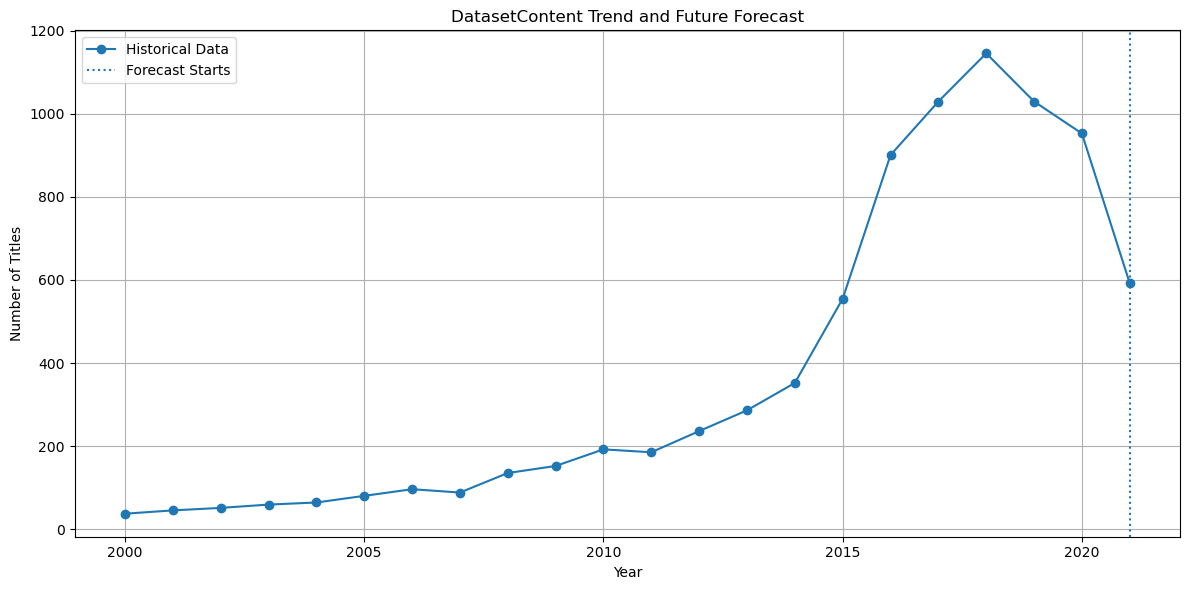

In [23]:
# Step 4: Visulize future predictions
plt.figure(figsize=(12, 6))
# Historical content
plt.plot(
    forecast_data["release_year"],
    forecast_data["content_count"],
    marker="o",
    label="Historical Data")
plt.axvline(
    last_year,
    linestyle=":",
    label="Forecast Starts")

plt.title("DatasetContent Trend and Future Forecast")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

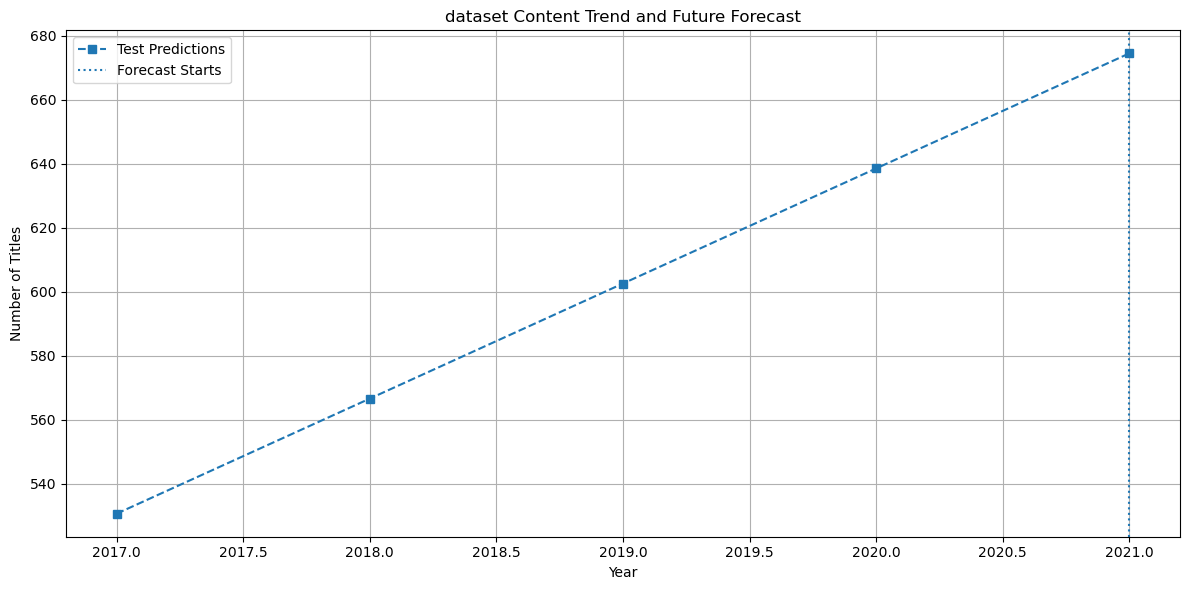

In [24]:
# Model predictions for test years
plt.figure(figsize=(12, 6))
plt.plot(
    X_test["release_year"],
    test_predictions,
    marker="s",
    linestyle="--",
    label="Test Predictions")
plt.axvline(
    last_year,
    linestyle=":",
    label="Forecast Starts")

plt.title("dataset Content Trend and Future Forecast")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

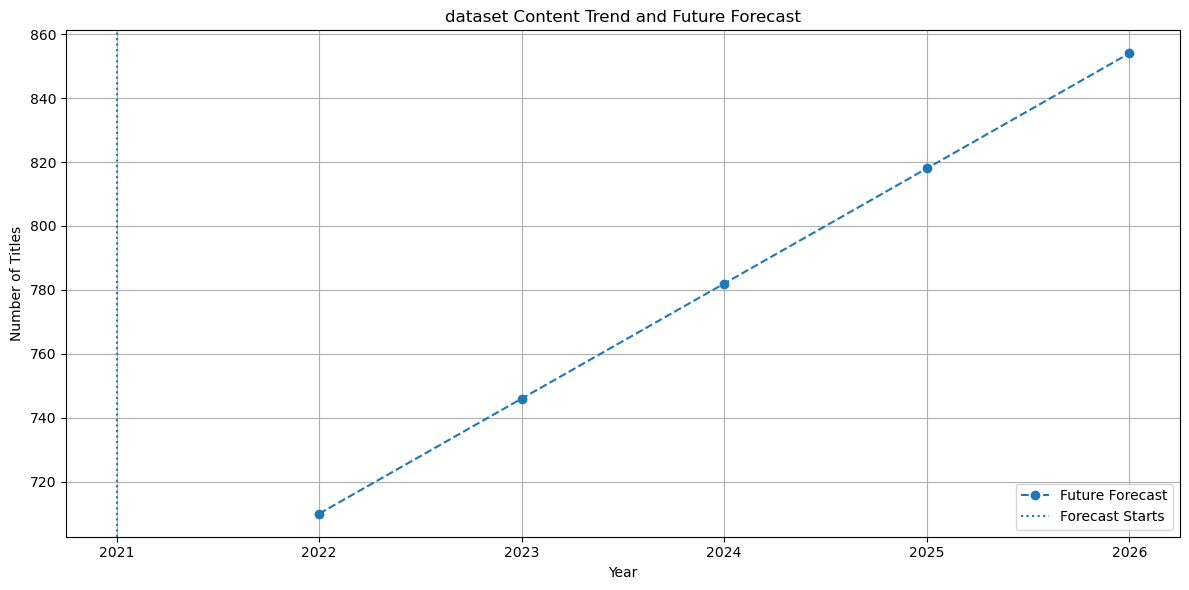

In [25]:
# Future predictions
plt.figure(figsize=(12, 6))
plt.plot(
    future_results["Year"],
    future_results["Predicted_Content_Count"],
    marker="o",
    linestyle="--",
    label="Future Forecast")
plt.axvline(
    last_year,
    linestyle=":",
    label="Forecast Starts")
plt.title("dataset Content Trend and Future Forecast")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [26]:
slope = model.coef_[0]

print("TREND ANALYSIS REPORT")
print("---------------------")

if slope > 0:
    print("Historical trend: Increasing")
elif slope < 0:
    print("Historical trend: Decreasing")
else:
    print("Historical trend: Nearly stable")

print("Estimated yearly change:", round(slope, 2),
      "titles per year")

print("\nFuture predictions:")
print(future_results.to_string(index=False))

print("\nModel evaluation:")
print("MAE:", round(mae, 2))
print("MSE:",round(mse,2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

TREND ANALYSIS REPORT
---------------------
Historical trend: Increasing
Estimated yearly change: 35.99 titles per year

Future predictions:
 Year  Predicted_Content_Count
 2022                      710
 2023                      746
 2024                      782
 2025                      818
 2026                      854

Model evaluation:
MAE: 380.66
MSE: 174719.57
RMSE: 417.99
R2 Score: -3.87


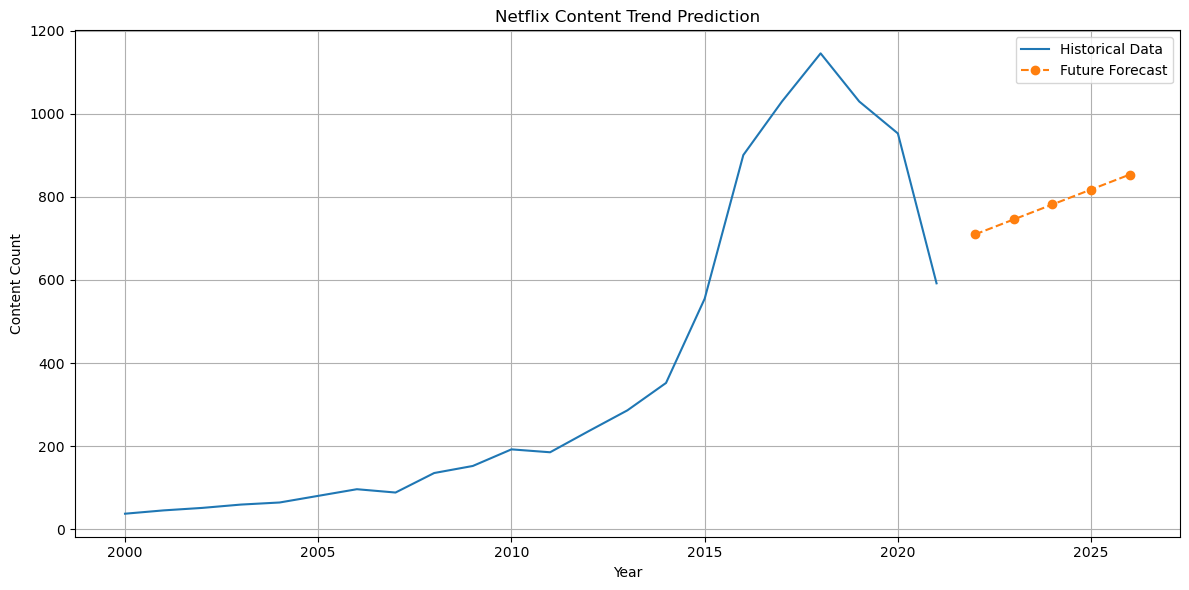

Files saved successfully!


In [18]:
# Save yearly data and future predictions
yearly_content.to_csv("yearly_content_trends.csv", index=False)
future_results.to_csv("future_content_predictions.csv", index=False)

# Save final visualization
plt.figure(figsize=(12, 6))
plt.plot(
    forecast_data["release_year"],
    forecast_data["content_count"],
    label="Historical Data"
)
plt.plot(
    future_results["Year"],
    future_results["Predicted_Content_Count"],
    marker="o",
    linestyle="--",
    label="Future Forecast"
)
plt.title("Netflix Content Trend Prediction")
plt.xlabel("Year")
plt.ylabel("Content Count")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("trend_prediction.png", dpi=300)
plt.show()

print("Files saved successfully!")